## MSE 401 Homework 8 Python Notebook

### Question 1

At 1 atm, compare ice phase ($\alpha$), liquid water ($L$), and water vapor ($G$) over the temperature range 200–450 K.

| Given property | Value |
|---|---:|
| Melting temperature $T_m$ | 273.15 K |
| Boiling temperature $T_b$ | 373.124 K |
| $S^L(298.15\,\mathrm K)$ | 69.95 J mol⁻¹ K⁻¹ |
| Enthalpy of fusion $\Delta H^{\alpha \rightarrow L}(T_m)$ | 6009.5 J mol⁻¹ |
| Enthalpy of vaporization $\Delta H^{L \rightarrow G}(T_b)$ | 40650 J mol⁻¹ |

The data below are sampled values calculated from published, experimentally assessed heat-capacity correlations. They are not independent experimental measurements. In this assignment, we neglect pressure dependence of the condensed phases and approximate the vapor by an ideal-gas heat capacity. Assume that the fitted heat-capacity functions can be extrapolated over the required temperature range for this exercise.

#### [**Tasks**]: Complete the indicated Python code to perform the required calculations.

#### [**Graded**]: Submit the specified equations, figures, numerical results, or explanations to Gradescope. 

**References:** 

[Sippola & Taskinen (2018), ice and water](https://pmc.ncbi.nlm.nih.gov/articles/PMC6150672/); 

[NASA Glenn, thermodynamic coefficients](https://www.grc.nasa.gov/www/winddocs/user/files.html); 

[NIST WebBook, water](https://webbook.nist.gov/cgi/cbook.cgi?ID=C7732185&Mask=187&Units=SI).

#### Provided data and imports

In [1]:
# ====================================================================
# Imports and Data: No modification requires. Run this cell directly.
# ====================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq
from matplotlib.ticker import AutoMinorLocator
from pathlib import Path

OUTPUT_DIR = Path("water_instructor_all_intersections_figures")
OUTPUT_DIR.mkdir(exist_ok=True)

# Thermodynamic properties
Tm, Tb, T0 = 273.15, 373.124, 298.15  # K
S_L0 = 69.95                          # J/(mol K)
DH_fus, DH_vap = 6009.5, 40650.0      # J/mol

# Load heat-capacity data from the CSV file.
# Keep the CSV file in the same folder as this Jupyter notebook.
(
    T_ice, Cp_ice_data,
    T_liquid, Cp_liquid_data,
    T_vapor, Cp_vapor_data
) = np.loadtxt(
    "water_heat_capacity.csv",
    delimiter=",",
    skiprows=1,
    unpack=True
)

print("Heat-capacity data successfully loaded.")
print(f"Ice: {len(T_ice)} data points")
print(f"Liquid: {len(T_liquid)} data points")
print(f"Vapor: {len(T_vapor)} data points")



Heat-capacity data successfully loaded.
Ice: 12 data points
Liquid: 12 data points
Vapor: 12 data points


#### Figure Formatting

In [2]:
# ====================================================================
# Figure Formatting: No modification required. Run this cell directly.
# ====================================================================
from matplotlib.ticker import AutoMinorLocator

COLORS = {"Ice": "#375A83", "Liquid": "#CA744C", "Vapor": "#347D86"}
MARKER_PURPLE = "#9060AE"


def format_figure(fig, ax, xlabel, ylabel, filename=None,
                  legend=True, legend_loc="upper right"):

    fig.set_size_inches(8.8, 6.2)

    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(2.0)

    ax.tick_params(which="major", direction="in",
                   top=True, right=True, length=8,
                   width=1.6, labelsize=12)

    ax.tick_params(which="minor", direction="in",
                   top=True, right=True, length=4,
                   width=1.1)

    ax.xaxis.set_minor_locator(AutoMinorLocator(4))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))

    ax.set_xlabel(xlabel, fontsize=16,
                  fontweight="bold", labelpad=9)

    ax.set_ylabel(ylabel, fontsize=16,
                  fontweight="bold", labelpad=9)

    ax.grid(False)

    if legend:
        ax.legend(frameon=False, fontsize=11,
                  loc=legend_loc)

    fig.tight_layout()

    if filename is not None:
        fig.savefig(OUTPUT_DIR / f"{filename}.png",
                    dpi=900, facecolor="white")
        fig.savefig(OUTPUT_DIR / f"{filename}.pdf",
                    facecolor="white")

    return fig, ax


def mark_intersection(ax, T_at, mu_at_kJ):
    """Mark an intersection using a purple dot."""

    ax.scatter(
        T_at, mu_at_kJ,
        s=115,
        color=MARKER_PURPLE,
        edgecolor="black",
        linewidth=1.3,
        zorder=7
    )


def plot_mu_three_phases(T_grid, mu_I, mu_L, mu_G,
                         filename, crossing_points=None):
    """Plot chemical potentials with intersections."""

    fig, ax = plt.subplots()

    ax.plot(T_grid, mu_I / 1000,
            color=COLORS["Ice"],
            lw=2.6, label="Ice")

    ax.plot(T_grid, mu_L / 1000,
            color=COLORS["Liquid"],
            lw=2.6, label="Liquid")

    ax.plot(T_grid, mu_G / 1000,
            color=COLORS["Vapor"],
            lw=2.6, label="Vapor")

    ax.set_xlim(200, 450)

    if crossing_points is not None:
        for T_at, mu_at in crossing_points:
            mark_intersection(ax, T_at, mu_at / 1000)

    # Chemical-potential legend: upper right
    format_figure(
        fig, ax,
        "Temperature (K)",
        r"Chemical potential, $\mu$ (kJ mol$^{-1}$)",
        filename,
        legend_loc="upper right"
    )

    plt.show()


**Supplmental Tutorial: `np.polyfit` and `np.polyval`**

Use the supplied tabulated heat capacities to create simple functions $C_P(T)$. The ice heat capacity is approximated by a **line**; liquid and vapor by **higher degree polynomials**.

$$
C_P^i(T)=\sum_{k=0}^{n}a_k^i x^k,
\qquad
x=\frac{T-300\,\mathrm{K}}{100\,\mathrm{K}}
$$

(I). `np.polyfit(x, y, degree)` returns the polynomial coefficients.

(II). `np.polyval(coefficients, x)` evaluates that polynomial.

(III). We fit the reduced variable `x = (T-300)/100` for numerical stability. Temperatures are still in K.

[**Task**] Complete this example below.


In [3]:
# ====================================================================
# Construct C_P(T) functions using np.polyfit and np.polyval. [Task]
# ====================================================================
# Reduced variable for polynomial fitting: x = (T - 300) / 100.
x_ice = (T_ice - 300) / 100
x_liquid = (T_liquid - 300) / 100
x_vapor = (T_vapor - 300) / 100

coef_ice = np.polyfit(x_ice, Cp_ice_data, 1)      # Example: Linear fit y = m*x + b
coef_liquid =  np.polyfit(x_liquid, Cp_liquid_data, 4)
coef_vapor = np.polyfit(x_vapor, Cp_vapor_data, 3)

# These are the fitted temperature-dependent Cp functions.
def Cp_ice(T):
    return np.polyval(coef_ice, (np.asarray(T) - 300) / 100) #Example

def Cp_liquid(T):
    return np.polyval(coef_liquid, (np.asarray(T) - 300) / 100)

def Cp_vapor(T):
    return np.polyval(coef_vapor, (np.asarray(T) - 300) / 100)

print("Ice polynomial coefficients:", coef_ice)
print("Liquid polynomial coefficients:", coef_liquid)
print("Vapor polynomial coefficients:", coef_vapor)


Ice polynomial coefficients: [13.04833699 41.25796062]
Liquid polynomial coefficients: [ 4.26971342 -6.30937961  4.50701303 -0.71325959 75.31633988]
Vapor polynomial coefficients: [-3.31602501e-02  2.40083520e-01  4.68412525e-01  3.35897181e+01]


#### Heat capacities, reference states, and integrals

[**Graded**] Report your curves and plots three molar heat capacity curves: $C_P^{i}(T)$.

Ice: Cp(T) = 13.04834x + 41.25796
where x = (T - 300)/100
Units: J mol^-1 K^-1

Liquid: Cp(T) = 4.26971x^4 - 6.30938x^3 + 4.50701x^2 - 0.71326x + 75.31634
where x = (T - 300)/100
Units: J mol^-1 K^-1

Vapor: Cp(T) = -0.03316x^3 + 0.24008x^2 + 0.46841x + 33.58972
where x = (T - 300)/100
Units: J mol^-1 K^-1



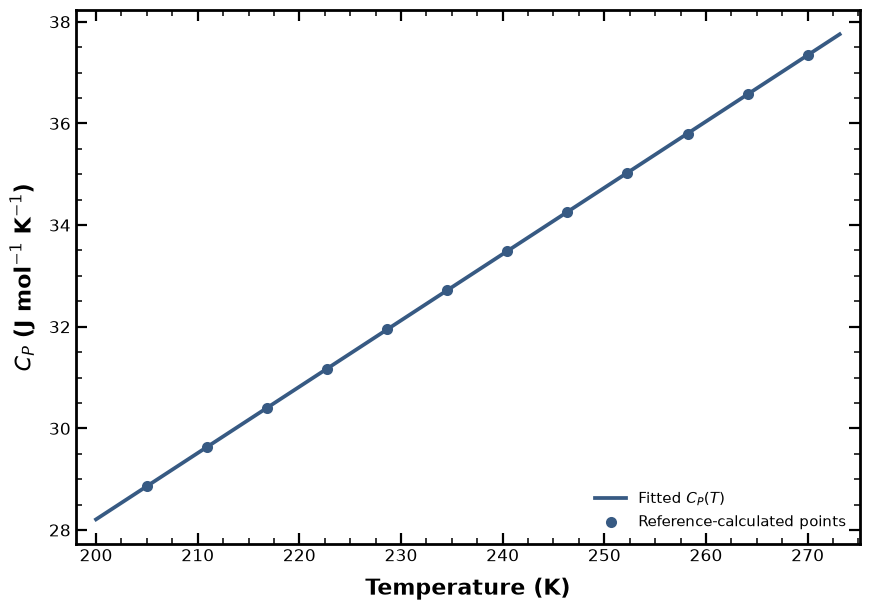

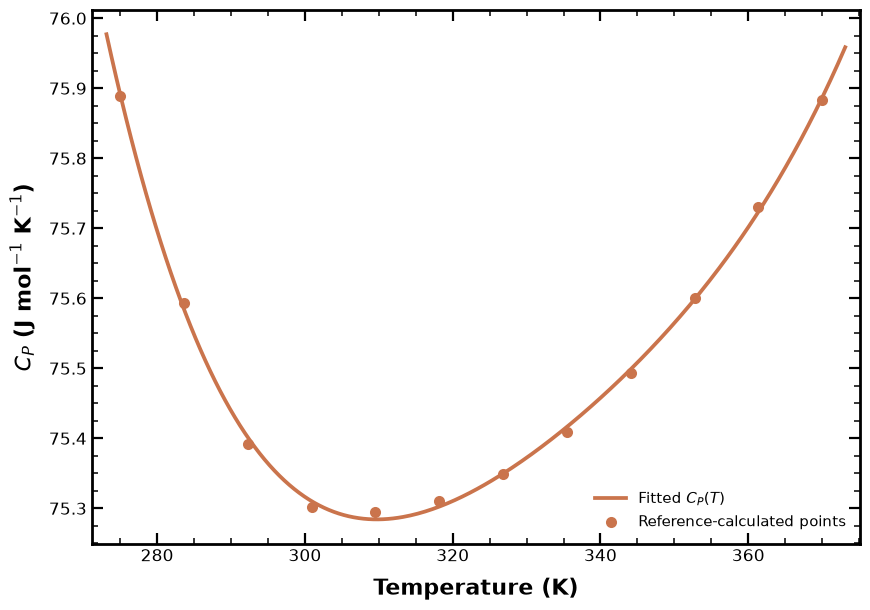

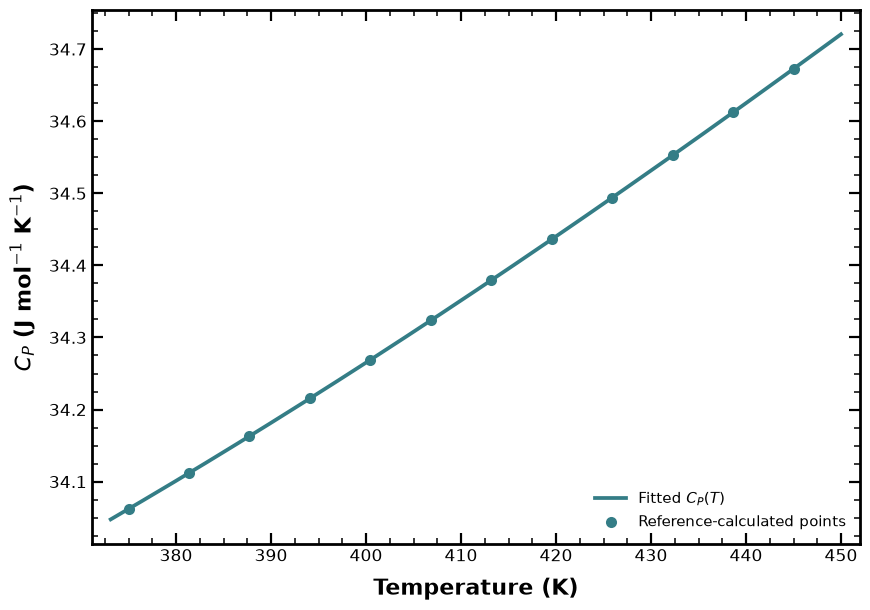

In [4]:
# ====================================================================
# Plot fitted C_P(T). Run directly. [Graded]
# ====================================================================
def print_fitted_equation(phase, coefficients):
    degree = len(coefficients) - 1
    terms = []

    for i, a in enumerate(coefficients):
        power = degree - i

        if power == 0:
            term = f"{abs(a):.5f}"
        elif power == 1:
            term = f"{abs(a):.5f}x"
        else:
            term = f"{abs(a):.5f}x^{power}"

        if i == 0:
            terms.append(("-" if a < 0 else "") + term)
        else:
            terms.append((" - " if a < 0 else " + ") + term)

    equation = "".join(terms)

    print(f"{phase}: Cp(T) = {equation}")
    print("where x = (T - 300)/100")
    print("Units: J mol^-1 K^-1\n")


# Provided plot function — creates ONE figure each time.
def plot_heat_capacity(T_data, Cp_data, Cp_function,
                       T_start, T_end, phase, filename):

    T_plot = np.linspace(T_start, T_end, 300)
    fig, ax = plt.subplots()

    ax.plot(
        T_plot, Cp_function(T_plot),
        lw=2.7, color=COLORS[phase],
        label="Fitted $C_P(T)$"
    )

    ax.scatter(
        T_data, Cp_data,
        s=42, facecolor=COLORS[phase],
        edgecolor=COLORS[phase],
        linewidth=1.5,
        label="Reference-calculated points"
    )

    ax.set_xlim(
        min(T_start, min(T_data)) - 2,
        max(T_end, max(T_data)) + 2
    )

    format_figure(
        fig, ax,
        "Temperature (K)",
        r"$C_P$ (J mol$^{-1}$ K$^{-1}$)",
        filename,
        legend_loc="lower right"
    )

    plt.show()


# Print fitted equations.
print_fitted_equation("Ice", coef_ice)
print_fitted_equation("Liquid", coef_liquid)
print_fitted_equation("Vapor", coef_vapor)

# Generate individual heat-capacity plots.
plot_heat_capacity(
    T_ice, Cp_ice_data, Cp_ice,
    200, Tm, "Ice", "cp_ice"
)

plot_heat_capacity(
    T_liquid, Cp_liquid_data, Cp_liquid,
    Tm, Tb, "Liquid", "cp_liquid"
)

plot_heat_capacity(
    T_vapor, Cp_vapor_data, Cp_vapor,
    Tb, 450, "Vapor", "cp_vapor"
)


**Supplemental tutorial: Evaluate integrals using `scipy.integrate.quad`**

Suppose you would like to evaluate:

$$
H(T_b)-H(T_a)=\int_{T_a}^{T_b} C_P(T)\,dT
$$

Then, you might execute in Python via:

```python
change_H, error_estimate = quad(Cp_liquid, Ta, Tb)
```

Another example: Note: The lambda expression defines a short function.

$$
S(T_b)-S(T_a)=\int_{T_a}^{T_b}\frac{C_P(T)}{T}\,dT
$$

```python
change_S, error_estimate = quad(lambda T: Cp_liquid(T) / T, Ta, Tb)
```

`quad(function, lower_limit, upper_limit)` returns **(integral, estimated numerical error)**. 

You might use `[0]` when you only need the integrated result.


#### Chemical Potentials

[**Graded**] For each phase $i \in \{\alpha, L, G\}$, write down the integral expressions for $H^i(T)$ and $S^i(T)$ in terms of heat capacity and the corresponding reference properties.

[**Task**] (I). Examine the reference molar enthalpy $H^i(T_{\mathrm{ref}}^i)$ and reference molar entropy $S^i(T_{\mathrm{ref}}^i)$ values. (Cell 1 below)

[**Task**] (II). Evaluate the chemical potentials $\mu^\alpha(T), \mu^L(T), \mu^G(T)$ with the integrals you wrote on paper. (Cells 2 and 3 below)

In [5]:
# ===========================================================================================
# Chemical Potential: Complete the function below. [Task]
# ===========================================================================================
def chemical_potential(T, Cp_function, T_ref, H_ref, S_ref): 
    change_H =  quad(Cp_function, T_ref, T)[0]
    change_S =  quad(lambda Teq: Cp_function(Teq)/Teq, T_ref, T)[0]
    H_T =  H_ref + change_H
    S_T =  S_ref + change_S
    return H_T - T * S_T


In [7]:
# =================================================================================================
# Reference Chemical Potentials: Use your integrals written on paper to complete this cell. [Task]
# =================================================================================================

# Initial conditions and constants.
Tm, Tb, T0 = 273.15, 373.124, 298.15  # K. We will set T0 as the reference temperature.
S_L0 = 69.95                          # J/(mol K)
DH_fus, DH_vap = 6009.5, 40650.0      # J/mol

# Reference point.
H_L0 = 0

# Liquid evaluated at melting temperature
H_Lm = H_L0 + quad(Cp_liquid, T0, Tm)[0]
S_Lm = S_L0 + quad(lambda Teq: Cp_liquid(Teq)/Teq, T0, Tm)[0]

# At melting point, solid and liquid coexist.
H_Im = H_Lm - DH_fus 
S_Im = S_Lm - DH_fus / Tm

# Liquid evaluated at boiling temperature
H_Lb = H_L0 + quad(Cp_liquid, T0, Tb)[0]
S_Lb = S_L0 + quad(lambda Teq: Cp_liquid(Teq)/Teq, T0, Tb)[0]

# At boiling point, liquid and vapor coexist
H_Gb = DH_vap + H_Lb
S_Gb = DH_vap / Tb + S_Lb

print("Reference states (H: J/mol; S: J/mol/K)")
print(f"Ice at {Tm:.3f} K: H={H_Im:.2f}, S={S_Im:.4f}")
print(f"Liquid at {T0:.3f} K: H={H_L0:.2f}, S={S_L0:.4f}")
print(f"Vapor at {Tb:.3f} K: H={H_Gb:.2f}, S={S_Gb:.4f}")


Reference states (H: J/mol; S: J/mol/K)
Ice at 273.150 K: H=-7898.81, S=41.3306
Liquid at 298.150 K: H=0.00, S=69.9500
Vapor at 373.124 K: H=46309.21, S=195.8241


**Check your results: You should obtain two values that are very close to 0 in the printed output below.**

In [17]:
# =================================================================================================
# Reference Chemical Potentials: Complete the functions in this cell. [Task]
# =================================================================================================
def mu_ice(T):
    return chemical_potential(T, Cp_ice, Tm, H_Im, S_Im) #Example

def mu_liquid(T):
    return chemical_potential(T, Cp_liquid, Tm, H_Lm, S_Lm)

def mu_vapor(T):
    return chemical_potential(T, Cp_vapor, Tb, H_Gb, S_Gb)

print("Check at melting point (should be close to 0): mu_ice - mu_liquid =", mu_ice(Tm) - mu_liquid(Tm), "J/mol")
print("Check at boiling point (should be close to 0): mu_liquid - mu_vapor =", mu_liquid(Tb) - mu_vapor(Tb), "J/mol")

Check at melting point (should be close to 0): mu_ice - mu_liquid = 0.0 J/mol
Check at boiling point (should be close to 0): mu_liquid - mu_vapor = 7.275957614183426e-12 J/mol


#### Free Energy Curve Analysis

**Supplemental tutorial: Finding phase intersections with `brentq`**

A pairwise intersection of chemical-potential curves satisfies

$$
\mu^i(T)-\mu^j(T)=0.
$$

You do not need to write your own root-finding algorithm.

`scipy.optimize.brentq(function, low, high)` finds a root between two temperatures **when the function has opposite signs at the interval endpoints**.

```python
T_cross = brentq(lambda T: mu_ice(T) - mu_liquid(T), 270, 276)
```

In [18]:
# =================================================================================================
# Find the temperature at which two phases have equal chemical potential. Run directly.
# =================================================================================================
from itertools import combinations
def find_all_intersections(mu_functions, T_grid):
    """
    Find all pairwise intersections of chemical potentials.

    Returns:
        (temperature, chemical_potential, phase1, phase2)
        Chemical potential is in J/mol.
    """

    crossings = []

    # Consider every pair of phases.
    for (phase1, mu1), (phase2, mu2) in combinations(
        mu_functions.items(), 2
    ):

        # Difference in chemical potential: mu1(T) - mu2(T)
        def difference(T):
            return mu1(T) - mu2(T)

        # Evaluate the difference across the temperature grid.
        delta_mu = np.array([difference(T) for T in T_grid])

        # Search for zero crossings between adjacent temperatures.
        for i in range(len(T_grid) - 1):

            Ta = T_grid[i]
            Tb = T_grid[i + 1]

            if delta_mu[i] == 0:
                T_cross = Ta

            elif delta_mu[i] * delta_mu[i + 1] < 0:
                T_cross = brentq(difference, Ta, Tb)

            else:
                continue

            mu_cross = mu1(T_cross)

            crossings.append(
                (T_cross, mu_cross, phase1, phase2)
            )

        # Include a root exactly at the last grid point.
        if delta_mu[-1] == 0:
            crossings.append(
                (T_grid[-1], mu1(T_grid[-1]), phase1, phase2)
            )

    # Sort intersections by increasing temperature.
    crossings.sort(key=lambda point: point[0])

    return crossings

#### Chemical potentials, all intersections, and phase stability

[**Graded**] (I). Plot $\mu^\alpha(T),\, \mu^L(T)$, and $\mu^G(T)$ from **200 to 450 K** in one figure. Show $\mu$ in kJ/mol.

[**Graded**] (II). Use the root finder to calculate all pairwise intersections: ice–liquid (A), ice–vapor (B), and liquid–vapor (C). Mark all points on the plot. (Run directly)

[**Graded**] (III) Do all intersections of the chemical-potential curves represent equilibrium phase transitions? If not, research the physical meaning of the other intersection(s) and briefly explain your findings.


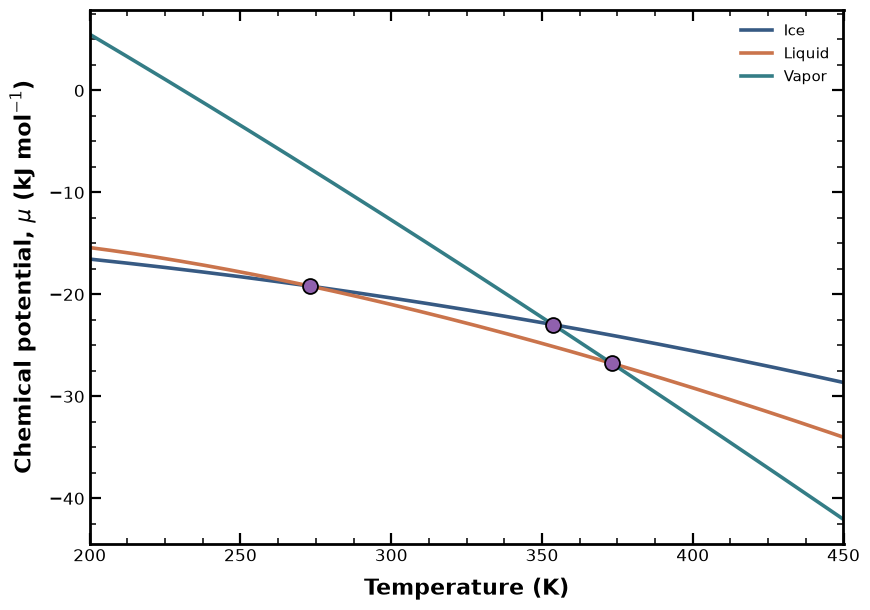

Pairwise chemical-potential intersections:
Ice = Liquid: T = 273.1500 K, mu = -19.1883 kJ/mol
Ice = Vapor: T = 353.6463 K, mu = -22.9609 kJ/mol
Liquid = Vapor: T = 373.1240 K, mu = -26.7575 kJ/mol

Chemical potentials at each intersection (kJ/mol):

T = 273.1500 K (Ice = Liquid)
  Ice:    -19.1883
  Liquid: -19.1883
  Vapor:  -7.6800

T = 353.6463 K (Ice = Vapor)
  Ice:    -22.9609
  Liquid: -25.1045
  Vapor:  -22.9609

T = 373.1240 K (Liquid = Vapor)
  Ice:    -24.0070
  Liquid: -26.7575
  Vapor:  -26.7575


In [19]:
# =================================================================================================
# Make the plot of all three chemical potentials over T. Run directly. [Graded]
# =================================================================================================

# Calculate chemical potentials over the temperature range.
T_grid = np.linspace(200, 450, 501)

mu_I = np.array([mu_ice(T) for T in T_grid])
mu_L = np.array([mu_liquid(T) for T in T_grid])
mu_G = np.array([mu_vapor(T) for T in T_grid])

# Define the chemical-potential functions.
mu_functions = {
    "Ice": mu_ice,
    "Liquid": mu_liquid,
    "Vapor": mu_vapor
}

# Automatically find all pairwise intersections.
all_crossings = find_all_intersections(mu_functions, T_grid)

# Extract coordinates (temperature, chemical potential).
# Chemical potentials are in J/mol.
crossing_points = [
    (T_cross, mu_cross)
    for T_cross, mu_cross, phase1, phase2 in all_crossings
]

# Plot all three curves and mark intersections.
# Legend location and marker formatting are defined
# inside plot_mu_three_phases().
plot_mu_three_phases(
    T_grid,
    mu_I,
    mu_L,
    mu_G,
    filename="mu_pairwise_intersections",
    crossing_points=crossing_points
)

# Report all intersection temperatures.
print("Pairwise chemical-potential intersections:")

for T_cross, mu_cross, phase1, phase2 in all_crossings:
    print(
        f"{phase1} = {phase2}: "
        f"T = {T_cross:.4f} K, "
        f"mu = {mu_cross/1000:.4f} kJ/mol"
    )

# Compare the chemical potentials of all three phases
# at each intersection.
print("\nChemical potentials at each intersection (kJ/mol):")

for T_cross, mu_cross, phase1, phase2 in all_crossings:
    print(f"\nT = {T_cross:.4f} K ({phase1} = {phase2})")
    print(f"  Ice:    {mu_ice(T_cross)/1000:.4f}")
    print(f"  Liquid: {mu_liquid(T_cross)/1000:.4f}")
    print(f"  Vapor:  {mu_vapor(T_cross)/1000:.4f}")

#### Constant heat capacity approximation

For each phase, replace $C_P^i(T)$ by its value at the corresponding phase reference temperature $T_m, T_0$, and $T_b$. Denote $c$ as constant, the expressions can be rewritten as:

$$
H^i_{c}(T)=H^i(T_r^i)+C^i_{P,c}(T-T_r^i),
\qquad
S^i_{c}(T)=S^i(T_r^i)+C^i_{P,c}\ln\left(\frac{T}{T_r^i}\right).
$$

**Optional**: Can you write done the derived results for constant $C_P$ from the integrals you wrote in (b)?

[**Graded**] Plot and determine the maximum absolute difference between the two equilibrium chemical potentials over 200–450 K. 

$$
\max_T \left|\mu_{eq}(T)-\mu_{eq}^{c}(T)\right|,
\qquad \mu_{eq}(T)=\min(\mu^\alpha,\mu^L,\mu^G).
$$

[**Graded**] Determine the maximum absolute difference and its corresponding temperature. Discuss the temperature regions where the constant approximation is less accurate.


Maximum absolute difference: 36.155 J/mol
Temperature: 200.000 K


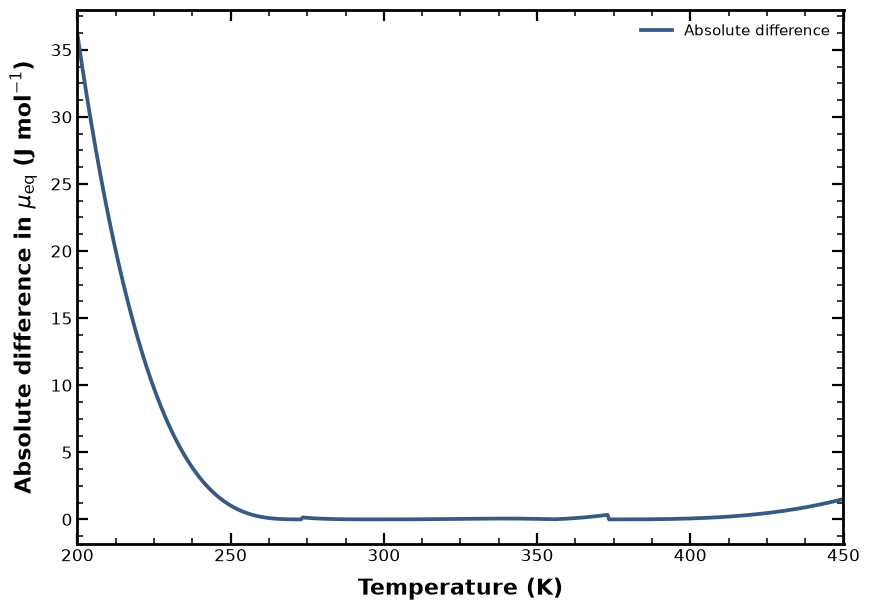

In [21]:
# ===========================================================================================
# Constant Approximation: Complete the cell below. [Graded]
# ===========================================================================================

# Evaluate constant Cp at each phase's reference temperature.
Cp_I_const = Cp_ice(Tm)
Cp_L_const = Cp_liquid(T0)
Cp_G_const = Cp_vapor(Tb)

# Calculate chemical potentials using constant Cp.
# H(T) = H_ref + Cp_const * (T - T_ref)
# S(T) = S_ref + Cp_const * ln(T / T_ref)
# mu(T) = H(T) - T * S(T)

# Example:  Ice
H_Ic = H_Im + Cp_I_const * (T_grid - Tm) 
S_Ic = S_Im + Cp_I_const * np.log(T_grid / Tm)
mu_Ic = H_Ic - T_grid * S_Ic

# [Task]: Complete the chemical potential for liquid at constant Cp.
H_Lc = H_L0 + Cp_L_const * (T_grid - T0)
S_Lc = S_L0 + Cp_L_const * np.log(T_grid / T0)
mu_Lc = H_Lc - T_grid * S_Lc

# [Task]: Complete the chemical potential for vapor at constant Cp.
H_Gc = H_Gb + Cp_G_const * (T_grid - Tb)
S_Gc = S_Gb + Cp_G_const * np.log(T_grid / Tb)
mu_Gc = H_Gc - T_grid * S_Gc




# Calculate equilibrium chemical potentials for both models.
mu_eq_variable = np.minimum.reduce([mu_I, mu_L, mu_G])
mu_eq_constant = np.minimum.reduce([mu_Ic, mu_Lc, mu_Gc])

# Calculate the absolute difference (J/mol).
error_mu = np.abs(mu_eq_variable - mu_eq_constant)

# Find the maximum absolute difference and its temperature.
index = np.argmax(error_mu)

print(f"Maximum absolute difference: {error_mu[index]:.3f} J/mol")
print(f"Temperature: {T_grid[index]:.3f} K")


# Plot the absolute difference.
fig, ax = plt.subplots()

ax.plot(
    T_grid, error_mu,
    lw=2.7,
    color=COLORS["Ice"],
    label="Absolute difference"
)

ax.set_xlim(200, 450)


format_figure(
    fig, ax,
    "Temperature (K)",
    r"Absolute difference in $\mu_{\mathrm{eq}}$ (J mol$^{-1}$)",
    "mu_difference",
    legend_loc="upper right"
)

plt.show()

